# 04 · Three traps, then the decision

Notebook 03 ended at "ship to 100%". This notebook checks the three things that most often
turn a winning dashboard into a losing launch:

1. **Peeking**: stopping the first time the p-value dips below 0.05.
2. **Novelty**: a lift that comes from the feature being new, and fades.
3. **A segment where the effect reverses**: hidden in the average and, here, hidden by novelty too.

Then the business recommendation.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import EXPERIMENT as E, EXPERIMENT_USERS, EXPERIMENT_SESSIONS, DATA_PROCESSED
from src.experiment import analysis, traps
from src.plotting import *

setup()
pd.set_option("display.precision", 4, "display.width", 140)
users_all = pd.read_parquet(EXPERIMENT_USERS)
sessions = pd.read_parquet(EXPERIMENT_SESSIONS)
users = users_all[users_all.full_7d_window]

## Trap 1 · Peeking
First, the theory: simulate 4,000 **A/A tests** (no true effect at all) at this test's traffic,
and check the p-value every day.

False positive rate, one look at the end:   5.2%
False positive rate, peeking every day:      28.6%


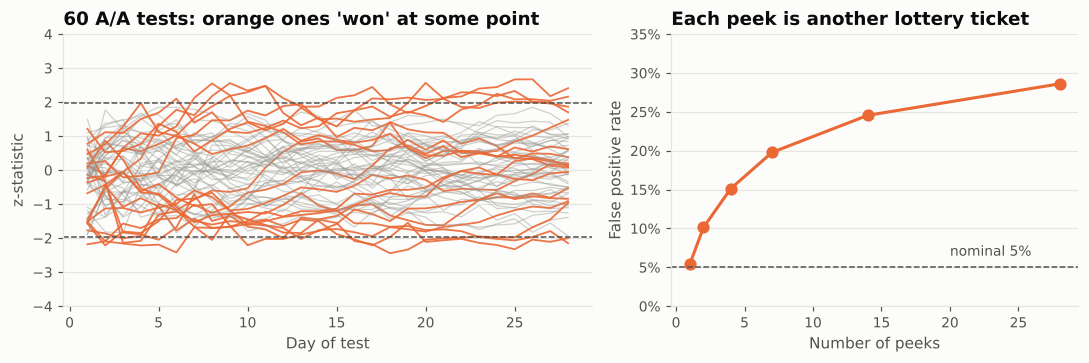

In [2]:
aa = traps.aa_peeking_simulation(p=E["baseline_rate"], n_per_day_per_arm=E["daily_eligible_users"] // 2,
                                 days=E["planned_days"])
print(f"False positive rate, one look at the end:   {aa['fpr_single_look']:.1%}")
print(f"False positive rate, peeking every day:      {aa['fpr_daily_peeking']:.1%}")
fpr = pd.Series(aa["fpr_by_number_of_peeks"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
crit = 1.96
for zpath in aa["z_paths"][:60]:
    crossed = (np.abs(zpath) > crit).any()
    ax.plot(np.arange(1, len(zpath) + 1), zpath, color=ORANGE if crossed else CONTROL,
            lw=1.2 if crossed else 0.8, alpha=0.9 if crossed else 0.45)
ax.axhline(crit, color=INK_2, lw=1, ls="--"); ax.axhline(-crit, color=INK_2, lw=1, ls="--")
ax.set_ylim(-4, 4); ax.set_xlabel("Day of test"); ax.set_ylabel("z-statistic")
ax.set_title("60 A/A tests: orange ones 'won' at some point")
ax = axes[1]
ax.plot(fpr.index, fpr.values, "o-", color=ORANGE, ms=7)
ax.axhline(0.05, color=INK_2, lw=1, ls="--"); ax.text(20, 0.065, "nominal 5%", color=INK_2, fontsize=9)
pct(ax); ax.set_ylim(0, 0.35); ax.set_xlabel("Number of peeks"); ax.set_ylabel("False positive rate")
ax.set_title("Each peek is another lottery ticket")
fig.tight_layout(); save(fig, "04_peeking_aa")

A z-statistic under the null is a random walk; give it 28 chances to cross ±1.96 and it will
around **29%** of the time, not 5%. Note that nothing is wrong with any single test: each daily
p-value is valid *on its own*. The error is the stopping rule.

**The fix we pre-registered:** 4 weekly looks with O'Brien-Fleming boundaries (strict early,
close to 1.96 at the end). Verify it actually holds α:

In [3]:
obf = traps.obf_fpr_check(p=E["baseline_rate"], n_per_week_per_arm=7 * E["daily_eligible_users"] // 2,
                          looks=E["interim_looks"])
print(f"OBF constant c = {obf['obf_c']:.3f}  →  boundaries {np.round(obf['z_boundaries'], 2)}")
print(f"A/A false positive rate with 4 OBF looks: {obf['fpr']:.1%}")

OBF constant c = 2.020  →  boundaries [4.04 2.86 2.33 2.02]
A/A false positive rate with 4 OBF looks: 5.0%


Now **what our own dashboard showed**, morning by morning (users exposed so far, conversions so far):

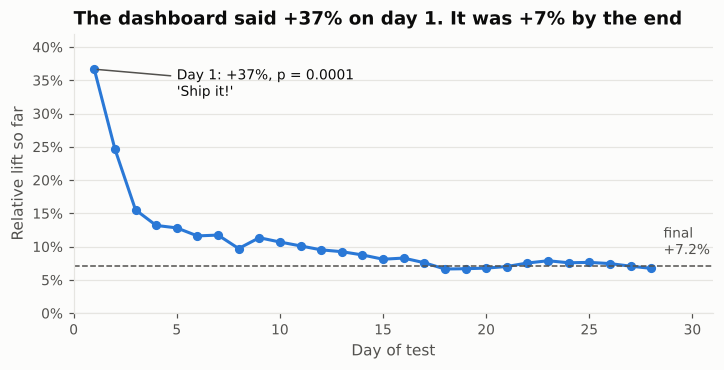

In [4]:
path = traps.observed_peeking_path(users_all, sessions, days=E["planned_days"])
final = analysis.compare_proportions(users, "converted_7d")["rel_lift"]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.plot(path.day, path.rel_lift, "o-", color=BLUE, ms=5)
ax.axhline(final, color=INK_2, lw=1, ls="--")
ax.text(28.6, final + 0.035, f"final\n{final:+.1%}", color=INK_2, fontsize=9, va="center")
first = path[path.p_value < 0.05].iloc[0]
ax.annotate(f"Day {int(first.day)}: {first.rel_lift:+.0%}, p = {first.p_value:.4f}\n'Ship it!'",
            (first.day, first.rel_lift), xytext=(5, first.rel_lift - 0.04), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK_2, lw=1))
pct(ax); ax.set_xlim(0, 31); ax.set_ylim(0, 0.42)
ax.set_xlabel("Day of test"); ax.set_ylabel("Relative lift so far")
ax.set_title("The dashboard said +37% on day 1. It was +7% by the end")
save(fig, "04_peeking_observed")

Here the effect is real, so peeking didn't produce a false *positive*; it produced a wildly
**inflated estimate**. A day-1 stop would have reported +37% to leadership, a number that comes
from novelty (everyone on day 1 is seeing the card for the first time) plus small-sample noise.
Early stopping biases effect sizes upward even when the direction is right: tests that get
stopped are disproportionately the ones that happened to look great.

## Trap 2 · Novelty
The right x-axis for novelty is **days since the user first saw the feature**, not calendar day.
Calendar day mixes users on their first visit with users on their twentieth.

,steady_state,novelty_bump,tau_days,steady_se
new,0.073,0.053,3.376,0.031
returning,-0.055,0.151,1.409,0.014
all,-0.017,0.127,2.121,0.014


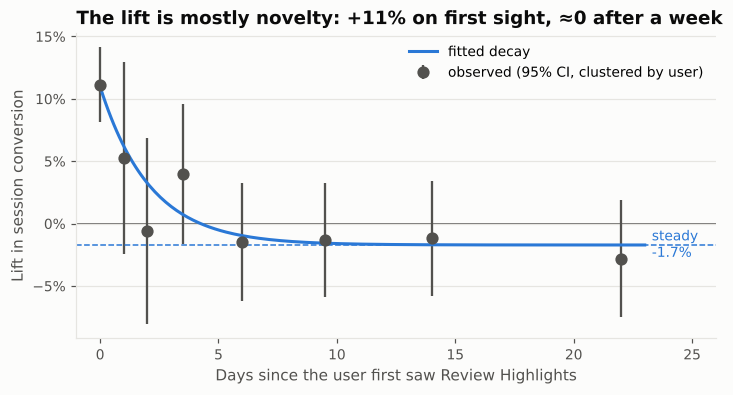

In [5]:
curve_all = traps.lift_by_exposure_age(sessions)
curve_seg = traps.lift_by_exposure_age(sessions, by="user_type")
fit_all = traps.fit_decay(curve_all)
fits = {lvl: traps.fit_decay(g) for lvl, g in curve_seg.groupby("level")}

fig, ax = plt.subplots(figsize=(7.5, 3.6))
k = np.linspace(0, 23, 200)
ax.errorbar(curve_all.mid, curve_all.rel_lift,
            yerr=[curve_all.rel_lift - curve_all.ci_low, curve_all.ci_high - curve_all.rel_lift],
            fmt="o", color=INK_2, ms=7, lw=1.5, capsize=0, label="observed (95% CI, clustered by user)")
f = fit_all
ax.plot(k, f["steady_state"] + f["novelty_bump"] * np.exp(-k / f["tau_days"]), color=BLUE, label="fitted decay")
ax.axhline(f["steady_state"], color=BLUE, lw=1, ls="--")
ax.text(23.3, f["steady_state"], f"steady\n{f['steady_state']:+.1%}", color=BLUE, fontsize=9, va="center")
zero_line(ax); pct(ax); ax.set_xlim(-1, 26)
ax.set_xlabel("Days since the user first saw Review Highlights"); ax.set_ylabel("Lift in session conversion")
ax.legend(loc="upper right"); ax.set_title("The lift is mostly novelty: +11% on first sight, ≈0 after a week")
save(fig, "04_novelty_overall")
pd.DataFrame({**fits, "all": fit_all}).T.round(3)

Fitting `lift(k) = steady + bump · e^(−k/τ)`:
* the novelty bump fades within a few days (τ ≈ 2 days, so it is ~90% gone by day 5), and
* the **overall steady-state lift is about −2% (CI includes 0)**. Once the card stops being new,
  it does nothing for the average user.

The 7-day primary metric could never show this: it is built from each user's *first* week, which
is exactly when novelty is strongest. A short-window metric on a new UI element will overstate
the long-run effect almost by construction.

## Trap 3 · The segment that reverses

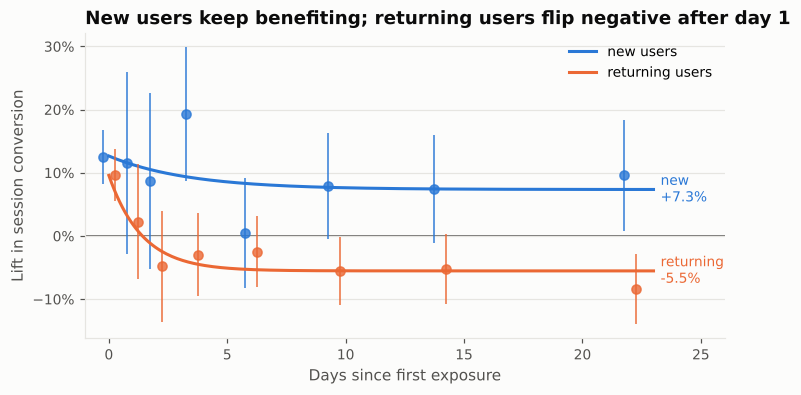

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for lvl, g in curve_seg.groupby("level"):
    c = SEGMENT_COLORS[lvl]; f = fits[lvl]
    off = -0.25 if lvl == "new" else 0.25
    ax.errorbar(g.mid + off, g.rel_lift, yerr=[g.rel_lift - g.ci_low, g.ci_high - g.rel_lift],
                fmt="o", color=c, ms=6, lw=1.2, alpha=0.8, capsize=0)
    ax.plot(k, f["steady_state"] + f["novelty_bump"] * np.exp(-k / f["tau_days"]), color=c, label=f"{lvl} users")
    ax.text(23.3, f["steady_state"], f"{lvl}\n{f['steady_state']:+.1%}", color=c, fontsize=9, va="center")
zero_line(ax); pct(ax); ax.set_xlim(-1, 26); ax.legend(loc="upper right")
ax.set_xlabel("Days since first exposure"); ax.set_ylabel("Lift in session conversion")
ax.set_title("New users keep benefiting; returning users flip negative after day 1")
save(fig, "04_reversal_by_segment")

In [7]:
lr = analysis.long_run_effect(sessions, by="user_type")
lr_all = analysis.long_run_effect(sessions)
display(pd.concat([lr, lr_all])[["level", "sessions", "cvr_control", "rel_lift", "rel_ci_low", "rel_ci_high",
                                 "p_value", "se_naive", "se_cluster"]])

,level,sessions,cvr_control,rel_lift,rel_ci_low,rel_ci_high,p_value,se_naive,se_cluster
0,new,76963,0.0862,0.0756,0.0287,0.1226,0.0016,0.0021,0.0021
1,returning,136689,0.1066,-0.0561,-0.0868,-0.0254,0.0003,0.0016,0.0017
0,all,213652,0.0992,-0.0143,-0.0400,0.0115,0.2770,0.0013,0.0013


Sessions 7+ days after first exposure, standard errors clustered by user:

| | 7-day metric (notebook 03) | Long run (day 7+) |
|---|---|---|
| **New users** | +11% | **+7.6%** (CI ≈ +3% to +12%) |
| **Returning users** | +3.7% ✅ | **−5.6%** (CI ≈ −8.7% to −2.5%) ❌ |
| **Everyone** | +7.2% | **−1.4%** (CI includes 0) |

For returning users the sign flips. Novelty made the card look positive in week one and masked
a lasting harm. Plausible mechanism (and a qualitative follow-up we'd run): returning users
already know what they want; the card pushes the menu below the fold and puts a caveat about
late deliveries on restaurants they *like*, which adds friction and doubt.

And returning users place most of the long-run orders, so their −5.6% outweighs the new users'
+7.6%. **Shipping to 100% would most likely lose orders once the novelty is gone.**

A note on the `se_naive` vs `se_cluster` columns: one user contributes many sessions, so
sessions are not independent. Here the two barely differ (most users have few sessions), but
on a metric like "page views", ignoring clustering can understate SEs by 2-3x. Analyze at the
unit you randomized, or cluster.

**Is this seed special?** No. Across 20 independent simulations:

In [8]:
rob = pd.read_csv(DATA_PROCESSED / "seed_robustness.csv")
pd.Series({
    "Headline 7-day lift significant": (rob.headline_p < 0.05).mean(),
    "Returning users look positive on the 7-day metric": (rob.returning_7d_lift > 0).mean(),
    "Returning users' long-run CI entirely below zero": (rob.longrun_returning_ci_high < 0).mean(),
    "Full rollout long-run effect ≤ 0": (rob.longrun_all <= 0).mean(),
}).map("{:.0%}".format).to_frame("share of 20 seeds")

,share of 20 seeds
Headline 7-day lift significant,100%
Returning users look positive on the 7-day metric,100%
Returning users' long-run CI entirely below zero,100%
Full rollout long-run effect ≤ 0,85%


## The decision, sized
Three options, judged on the **steady-state** effect, because that's what we live with after
launch. Volumes are an explicit assumption: replace them with your platform's numbers.

In [9]:
MONTHLY_ORDERS = 1_000_000          # assumption: monthly orders from traffic like the test's
AOV = sessions.loc[sessions.ordered == 1, "order_value"].mean()

lr_i = lr.set_index("level")
ctrl_lr = sessions[(sessions.variant == "control") & (sessions.days_since_exposure >= 7)]
share = ctrl_lr.groupby("user_type").ordered.sum() / ctrl_lr.ordered.sum()

def scenario(name, lift, lo, hi):
    return {"option": name, "steady-state order change": lift, "95% CI low": lo, "95% CI high": hi,
            "orders / month": lift * MONTHLY_ORDERS, "revenue / month (R$)": lift * MONTHLY_ORDERS * AOV}

new_only = share["new"] * lr_i.loc["new"]
sc = pd.DataFrame([
    scenario("A. Ship to everyone", lr_all.rel_lift.iloc[0], lr_all.rel_ci_low.iloc[0], lr_all.rel_ci_high.iloc[0]),
    scenario("B. Ship to new users only", new_only.rel_lift, new_only.rel_ci_low, new_only.rel_ci_high),
    scenario("C. Don't ship", 0.0, 0.0, 0.0),
])
print(f"Share of long-run orders from new users: {share['new']:.0%} · AOV ≈ R${AOV:.0f}")
sc.style.hide(axis="index").format({"steady-state order change": "{:+.2%}", "95% CI low": "{:+.2%}", "95% CI high": "{:+.2%}",
                 "orders / month": "{:+,.0f}", "revenue / month (R$)": "{:+,.0f}"})

Share of long-run orders from new users: 31% · AOV ≈ R$57


option,steady-state order change,95% CI low,95% CI high,orders / month,revenue / month (R$)
A. Ship to everyone,-1.43%,-4.00%,+1.15%,"-14,263","-812,441"
B. Ship to new users only,+2.38%,+0.90%,+3.86%,"+23,817","+1,356,629"
C. Don't ship,+0.00%,+0.00%,+0.00%,+0,+0


Option B is the only one whose interval excludes a loss. It is smaller than the headline
promised (+7.2% was never real), but it is positive, and it compounds: the 7-day metric also
showed new users **activating** faster (+11% first-week conversion), and a first order is the
strongest predictor of a second.

## Recommendation

**1. Product: ship Review Highlights to new users only. Do not ship to returning users.**
Define "new" as fewer than 2 lifetime orders; switch the card off after the 2nd order. Keep a
10% holdout of new users for 8 weeks to confirm the steady-state lift holds.

**2. Marketing direction: use review-derived social proof for *acquisition*, not retention.**
The experiment says the same content that helps a first-time user decide gets in the way of a
loyal one. So:
* Put "what reviewers love" (taste and friendly staff are the most-praised aspects, notebook 01)
  into **acquisition surfaces**: SEO restaurant pages, paid-social creatives, first-order
  onboarding emails, app-store screenshots.
* **Keep it out of CRM to existing customers.** Retention messaging should be about their own
  history: reorder their usual, favorites back in stock, loyalty perks.
* Each of those is a new hypothesis. Test them with the same discipline: power analysis first,
  ≥3-week runtime for anything new-looking, steady-state read, pre-registered segments.

**3. Do not promise speed. Fix it.** Delivery delay is the costliest complaint (≈41% of 1-2★
reviews, ≈1.2★ lost when it happens). A "fast delivery" campaign would send new customers
straight into the platform's #1 cause of 1★ reviews, and we'd pay to acquire churn. Marketing's
lever here is **honest ETAs and a late-delivery credit**, owned jointly with Ops, tested on
returning users with 30-day retention as the primary metric.

**4. Don't act on the city-tier result.** It is noise by construction, did not replicate in the
later window, and has no mechanism. If anyone wants a regional strategy, that's a new test.

**5. Process changes for every future test.** Pre-registered O'Brien-Fleming looks (no ad-hoc
stops); minimum 3 weeks for UI changes; decision metric = post-novelty effect; interaction tests,
not "significant here, not there".

---
*Caveat that applies to all of the above: the reviews and the experiment are simulated. The
methods and the reasoning transfer; the specific numbers do not. Replace the data with real
reviews and a real test before quoting any figure to a stakeholder.*